<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/03_computer_vision/11_depth_estimation_bonus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌄 Bonus · Monocular depth estimation: seeing in 3D with one eye

Close one eye: you still know the cup is closer than the wall. Your brain uses **cues**: perspective lines, the known
size of objects, occlusion (what hides what), texture getting finer with distance, haze on far mountains.
**Monocular depth estimation** teaches a network to do the same: from **one single image**, predict the distance of
every pixel to the camera.

It's used in robotics and drones (obstacle avoidance with a cheap camera), augmented reality (placing virtual objects
behind real ones), the "portrait mode" of phones, 3D photos, and as an input for self-driving perception.

**A short history**
- **2005 · Make3D** (Stanford): depth from a single image with hand-crafted features.
- **2012 · NYU Depth v2**: indoor scenes filmed with a Microsoft Kinect, which measures depth with infrared light.
  Those measurements become the "ground truth" for learning.
- **2014 · Eigen et al.**: the first deep CNN predicting depth maps.
- **2019 → today**: MiDaS, DPT, *Depth Anything* train on millions of images; and compact models like **YOLO26-depth**
  run in real time.

**Your mission:** predict depth maps, measure their quality with the standard metrics, and build two fun
applications: a **portrait mode** and a **3D point cloud**.

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

os.environ["YOLO_VERBOSE"] = "False"
from ultralytics import YOLO
from ultralytics.utils import ASSETS, YAML
from ultralytics.utils.checks import check_yaml

DEVICE = get_device()
quest("Seeing in 3D with one eye", chapter="Track 3 · Computer vision · Bonus", xp=150)

⚙️  Using device: mps  (Apple Silicon GPU (Metal))
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Seeing in 3D with one eye
   Track 3 · Computer vision · Bonus
   Reward: up to 150 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Data: images + measured depth 📏

`depth8` is a tiny sample (8 indoor images, 1 MB) from NYU-style datasets: for each RGB image, a 16-bit PNG stores the
depth measured by a sensor, **in millimetres** (value 1000 = 1 metre; 0 = no measurement).

In [3]:
cfg = YAML.load(check_yaml("depth8.yaml"))
folder = DATA_DIR / "yolo_datasets" / Path(cfg["path"]).name
if not folder.exists():
    archive = download(cfg["download"], DATA_DIR / "yolo_datasets" / Path(cfg["download"]).name)
    extract(archive, DATA_DIR / "yolo_datasets"); archive.unlink()

pairs = []
for img_path in sorted((folder / "images").rglob("*.jpg")):
    split = img_path.parent.name
    depth_path = folder / "depth" / split / (img_path.stem + ".png")
    if depth_path.exists():
        rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        depth_m = cv2.imread(str(depth_path), cv2.IMREAD_UNCHANGED).astype(np.float32) / cfg["depth_scale"]
        pairs.append((img_path, rgb, depth_m))
print(f"{len(pairs)} image/depth pairs · depth range {min(d[d > 0].min() for *_, d in pairs):.2f} m → "
      f"{max(d.max() for *_, d in pairs):.2f} m")

8 image/depth pairs · depth range 0.53 m → 3.82 m


## 2. Predict depth with YOLO26n-depth 🔮

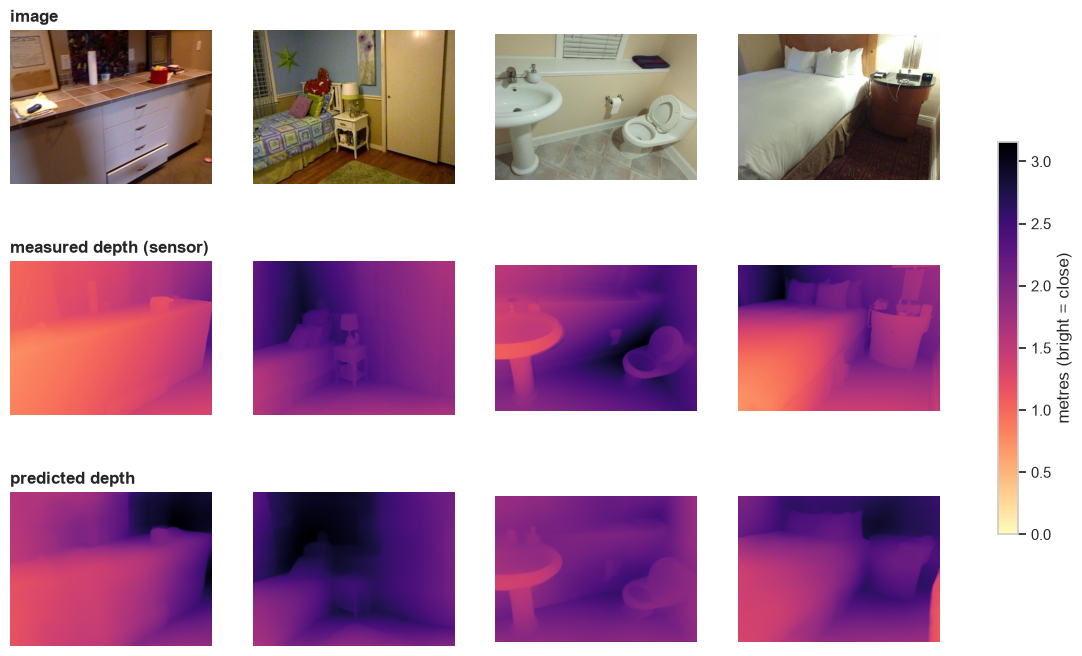

In [4]:
model = YOLO(str(DATA_DIR / "weights" / "yolo26n-depth.pt"))
preds = [model.predict(str(p), device=DEVICE)[0].depth.data.cpu().numpy() for p, _, _ in pairs]

fig, axes = plt.subplots(3, 4, figsize=(15, 8.5))
for k in range(4):
    _, rgb, gt = pairs[k]
    pred = cv2.resize(preds[k], (gt.shape[1], gt.shape[0]))
    vmax = max(gt.max(), pred.max())
    axes[0, k].imshow(rgb)
    axes[1, k].imshow(np.where(gt > 0, gt, np.nan), cmap="magma_r", vmin=0, vmax=vmax)
    im = axes[2, k].imshow(pred, cmap="magma_r", vmin=0, vmax=vmax)
for ax in axes.ravel():
    ax.axis("off")
for r, t in enumerate(["image", "measured depth (sensor)", "predicted depth"]):
    axes[r, 0].set_title(t, loc="left")
fig.colorbar(im, ax=axes, shrink=0.6, label="metres (bright = close)")
plt.show()

## 3. How good is it? The standard depth metrics 📊

Only pixels with a valid measurement (`> 0`) are evaluated:
- **AbsRel**: mean of |pred − true| / true, the average *relative* error (0.10 = 10% off),
- **RMSE**: root mean squared error in metres,
- **δ < 1.25**: share of pixels where the prediction is within ±25% of the truth (higher is better).

*Scale ambiguity:* from a single image, a toy house close up looks like a real house far away. Many models predict
depth only "up to a scale"; a common protocol rescales predictions by the ratio of medians. We report both.

In [5]:
def depth_metrics(pred, gt):
    pred = cv2.resize(pred, (gt.shape[1], gt.shape[0]))
    m = gt > 0
    p, t = pred[m], gt[m]
    ratio = np.maximum(p / t, t / p)
    return {"AbsRel": np.mean(np.abs(p - t) / t), "RMSE_m": np.sqrt(np.mean((p - t) ** 2)), "δ<1.25": np.mean(ratio < 1.25)}

raw = pd.DataFrame([depth_metrics(p, gt) for p, (_, _, gt) in zip(preds, pairs)])
scaled = pd.DataFrame([depth_metrics(p * np.median(gt[gt > 0]) / np.median(cv2.resize(p, (gt.shape[1], gt.shape[0]))[gt > 0]), gt)
                       for p, (_, _, gt) in zip(preds, pairs)])
summary = pd.DataFrame({"metric scale": raw.mean(), "median-scaled": scaled.mean()}).round(3)
summary

,metric scale,median-scaled
AbsRel,0.268,0.097
RMSE_m,0.497,0.212
δ<1.25,0.561,0.879


**Reading the table:** once the global scale is corrected (median scaling), the relative error drops a lot and most
pixels land within ±25% of the truth. The model gets the **shape** of the scene (what is in front of what) much
better than its **absolute size**: exactly the scale ambiguity of a single image. Apps that need metres usually add a
reference (a known object size, a second camera, or a depth sensor).

In [6]:
checkpoint("depth/metrics", xp=40)

✅ Checkpoint · depth/metrics (+40 XP)
   █████████░░░░░░░░░░░░░░░ 40/100 XP


## 4. Fun application #1: portrait mode 📸

Phones blur the background to imitate expensive lenses. With a depth map it's simple: keep pixels **close** to the
subject sharp, blur the rest progressively.

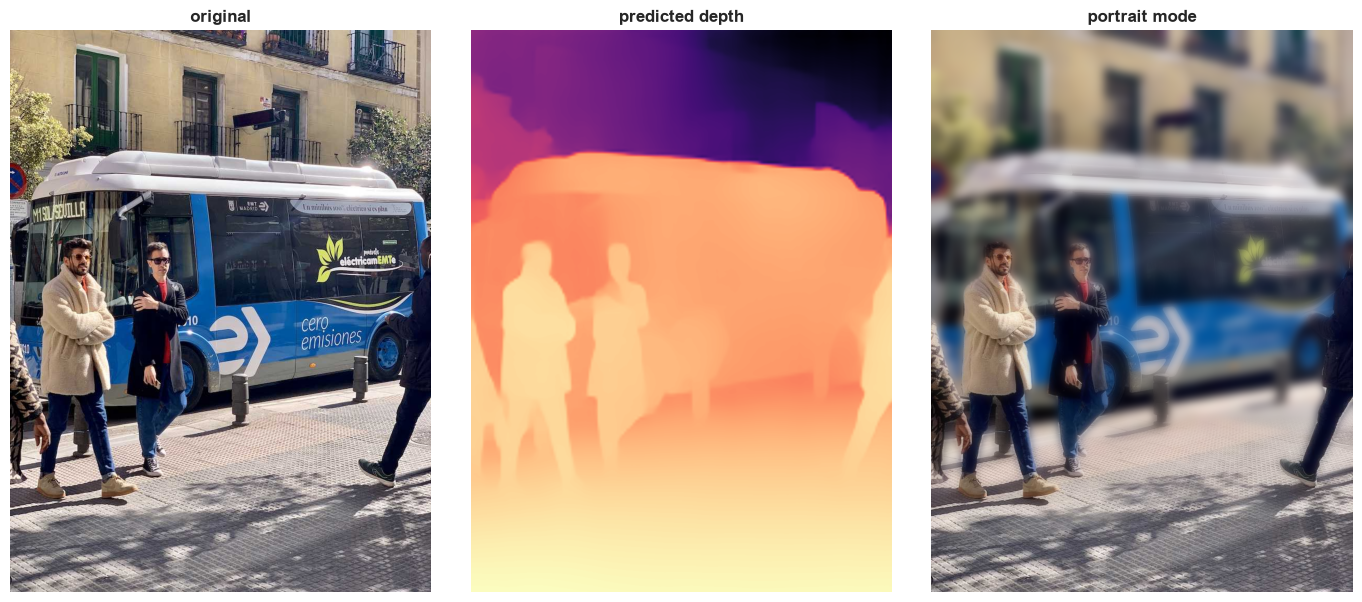

In [7]:
bus = cv2.cvtColor(cv2.imread(str(ASSETS / "bus.jpg")), cv2.COLOR_BGR2RGB)
d = cv2.resize(model.predict(str(ASSETS / "bus.jpg"), device=DEVICE)[0].depth.data.cpu().numpy(), (bus.shape[1], bus.shape[0]))
focus = np.percentile(d, 5)                                       # the closest things in the scene are the subject
weight = np.clip((d - focus) / (np.percentile(d, 60) - focus), 0, 1)[..., None]
blurred = cv2.GaussianBlur(bus, (0, 0), 9)
portrait = (bus * (1 - weight) + blurred * weight).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(14, 6))
for ax, img, t in zip(axes, [bus, d, portrait], ["original", "predicted depth", "portrait mode"]):
    ax.imshow(img, cmap="magma_r" if img.ndim == 2 else None); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Fun application #2: a 3D point cloud 🧊

With a depth value per pixel and a (guessed) camera focal length, each pixel can be lifted into 3D with the
**pinhole camera** model: `X = (u − cx) · Z / f`, `Y = (v − cy) · Z / f`, `Z = depth`.

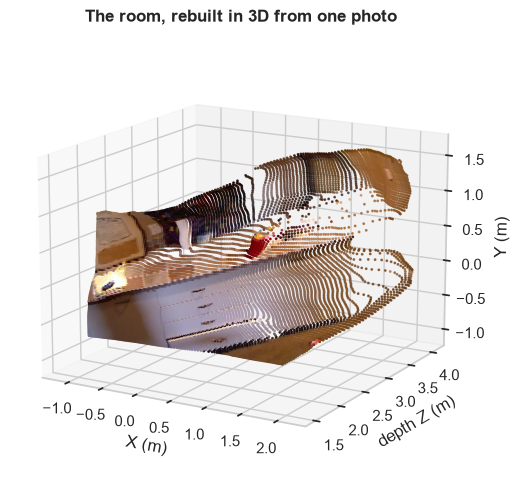

In [8]:
_, rgb, _ = pairs[0]
z = cv2.resize(preds[0], (rgb.shape[1], rgb.shape[0]))
h, w = z.shape
f = 0.9 * w                                                     # a typical focal length for a phone/Kinect camera
v, u = np.mgrid[0:h:4, 0:w:4]                                    # one point every 4 pixels
Z = z[::4, ::4]
X, Y = (u - w / 2) * Z / f, (v - h / 2) * Z / f
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(projection="3d")
ax.scatter(X.ravel(), Z.ravel(), -Y.ravel(), c=rgb[::4, ::4].reshape(-1, 3) / 255, s=1)
ax.set(xlabel="X (m)", ylabel="depth Z (m)", zlabel="Y (m)", title="The room, rebuilt in 3D from one photo")
ax.view_init(elev=15, azim=-60); plt.show()

## 🏁 Bonus complete!

### 🚀 Your turn (bonus XP)
1. Take a photo with your phone and run the portrait mode on it.
2. Compute the metrics per depth range (0-2 m, 2-4 m, > 4 m): where is the model worst?
3. Use depth + YOLO detection to estimate **how far each person is** in a street photo.
4. Fine-tune: `model.train(data="depth8.yaml", ...)` works like the other tasks (you'll need a real dataset such as
   `nyu-depth.yaml` to make it useful).

In [9]:
checkpoint("depth/complete", xp=110)
badge("Depth Seer", "🌄")
progress()

✅ Checkpoint · depth/complete (+110 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ██████░░░░░░░░░░░░░░░░░░ 150/300 XP
╔═══════════════════════════════╗
║ 🌄  BADGE UNLOCKED: Depth Seer ║
╚═══════════════════════════════╝
🐣 Data Explorer
██████░░░░░░░░░░░░░░░░░░ 150/300 XP
Checkpoints unlocked: 2
Badges: 🌄 Depth Seer
